# Nifty 50 Overnight Strategy - Backtest

**Strategy:** buy Nifty 50 futures at the close and sell them at the next day's open. Only trade on nights where the next trading day is the next calendar day (so weekends and holidays are skipped).

- Instrument: Nifty 50 near month futures. I use the spot index and subtract the futures carry separately.
- Position size: 1x capital
- Transaction costs: 2 bp per side
- Cash: the whole capital earns the India call money rate

Everything runs offline from the csv files in `data/`. Only pandas, numpy and matplotlib are used.

### Hypothesis
1. A lot of information comes out while the Indian market is closed - US close, Asian open, macro data, company results, geopolitics. Most of it arrives between 15:30 and 09:15 IST when someone holding Nifty can't trade. Taking this gap risk should be paid a premium, so the overnight (close to open) return should be positive on average.
2. Most of the selling happens during the day. Day traders square off before the close, institutions sell through the session with VWAP orders, and retail investors tend to buy at the open. So the intraday (open to close) return should be flat or negative. This is the "tug of war" from Lou, Polk & Skouras (2019), Cooper, Cliff & Gulen (2008) found the same thing in the US.
3. Not every night is the same. A weekend or holiday gap has 2-5 calendar days of futures premium decay but only one night of news. So these nights are skipped because of the cost, not because of anything in the data.

### In-sample / out-of-sample
All the parameters below were fixed before looking at the out-of-sample period. The rules were only checked on 2010-2018, and 2019-2026 was run once (by running this notebook). Section 8 shows how the results change with different parameters in both periods.

In [1]:
import os
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# plot settings
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

colors = {
    "strat": "#1f3a5f",
    "nifty": "#9a9a9a",
    "overnight": "#2a9d8f",
    "intraday": "#e76f51",
    "cash": "#e9c46a",
    "insample": "#f2f2f2",
}

# ---------- parameters (fixed before running the out-of-sample period) ----------
COST_SIDE = 0.0002      # 2 bp per side (about 1.3 bp fees + 0.7 bp slippage, see section 7)
DIV_YIELD = 0.012       # Nifty dividend yield used in the futures carry (rf - q), 1.2% is roughly the long run average
MAX_GAP_DAYS = 1        # only hold nights that are this many calendar days long (1 = skip weekends and holidays)
FEAR_FILTER = False     # optional: stay flat when VIX >= FEAR_RATIO * its 60 day average
FEAR_RATIO = 1.3
VOL_TARGET = None       # optional: annual vol target for the overnight returns (None = always 1x)
MAX_LEVERAGE = 1.0

START = "2010-01-01"
IS_END = "2018-12-31"     # in-sample period (rules checked here)
OOS_START = "2019-01-01"  # out-of-sample period (run once)

RF_FALLBACK = 6.5       # % per year, only used if the FRED file is missing
CAPITAL = 1e7           # Rs 1 crore, just for reference. All results are in % of capital

os.makedirs("results", exist_ok=True)

params = {
    "cost_side": COST_SIDE,
    "div_yield": DIV_YIELD,
    "max_gap_days": MAX_GAP_DAYS,
    "fear_filter": FEAR_FILTER,
    "fear_ratio": FEAR_RATIO,
    "vol_target": VOL_TARGET,
    "max_leverage": MAX_LEVERAGE,
    "start": START,
    "is_end": IS_END,
    "oos_start": OOS_START,
    "rf_fallback": RF_FALLBACK,
    "capital_inr": CAPITAL,
}
with open("results/params.json", "w") as f:
    json.dump(params, f, indent=2)

params

{'cost_side': 0.0002,
 'div_yield': 0.012,
 'max_gap_days': 1,
 'fear_filter': False,
 'fear_ratio': 1.3,
 'vol_target': None,
 'max_leverage': 1.0,
 'start': '2010-01-01',
 'is_end': '2018-12-31',
 'oos_start': '2019-01-01',
 'rf_fallback': 6.5,
 'capital_inr': 10000000.0}

## 1. Data

| File | Source | Content |
|---|---|---|
| `data/nifty50.csv` | Yahoo Finance `^NSEI` (NSE official open and close) | daily OHLC, 2009-01-02 to 2026-09-18 |
| `data/india_vix.csv` | Yahoo Finance `^INDIAVIX` | daily, same dates. Only used for the optional fear filter and the risk section |
| `data/india_short_rate_fred.csv` | FRED `IRSTCI01INM156N`, India call money rate, monthly % p.a. | cash return and futures carry |

The Nifty trading days are used as the main index.
- `r_on[t] = Open[t] / Close[t-1] - 1` is the overnight return into day t
- `r_id[t] = Close[t] / Open[t] - 1` is the intraday return of day t
- `gap[t]` is the number of calendar days between day t-1 and day t

In [2]:
nifty = pd.read_csv("data/nifty50.csv", index_col=0, parse_dates=True)
nifty = nifty.sort_index()
vix = pd.read_csv("data/india_vix.csv", index_col=0, parse_dates=True)
vix = vix.sort_index()

# monthly call money rate (% per year)
try:
    rate_data = pd.read_csv("data/india_short_rate_fred.csv", index_col=0, parse_dates=True)
    rf_monthly = pd.to_numeric(rate_data.iloc[:, 0], errors="coerce").dropna()
    rf_source = "FRED IRSTCI01INM156N"
except FileNotFoundError:
    rf_monthly = pd.Series(RF_FALLBACK, index=pd.to_datetime([START]))
    rf_source = "constant " + str(RF_FALLBACK) + "%"

df = pd.DataFrame({"open": nifty["Open"], "close": nifty["Close"]})

# VIX close on the Nifty dates, forward fill any missing days
df["vix"] = vix["Close"].reindex(df.index).ffill()

# for each day use the latest monthly rate
df["rf_pa"] = rf_monthly.reindex(df.index, method="ffill").ffill() / 100
df["rf"] = df["rf_pa"] / 252   # daily cash return

df["ret"] = df["close"].pct_change()                 # close to close
df["r_on"] = df["open"] / df["close"].shift(1) - 1   # overnight: previous close to today's open
df["r_id"] = df["close"] / df["open"] - 1            # intraday: open to close

# calendar days since the previous trading day
dates = pd.Series(df.index, index=df.index)
df["gap"] = dates.diff().dt.days

# some basic checks on the data
assert df["open"].notna().all()
assert df["close"].notna().all()
assert df["vix"].notna().all()
assert df.index.is_unique

print("Rows:", len(df), "|", df.index[0].date(), "to", df.index[-1].date())
print(f"Cash rate: {rf_source}, latest value {df['rf_pa'].iloc[-1]:.2%}")
print("Days where open == close:", (df["open"] == df["close"]).sum())

df[["ret", "r_on", "r_id", "gap"]].describe().T[["mean", "std", "min", "max"]]

Rows: 4346 | 2009-01-02 to 2026-09-18
Cash rate: FRED IRSTCI01INM156N, latest value 5.50%
Days where open == close: 1


,mean,std,min,max
ret,0.000533,0.011313,-0.129805,0.177441
r_on,0.000971,0.005910,-0.091448,0.048614
r_id,-0.000435,0.009866,-0.068180,0.176960
gap,1.488608,0.898086,1.000000,6.000000


## 2. Looking at the raw data (no costs, no carry)
Where does the Nifty return actually come from? Below is the cumulative overnight vs intraday vs close to close return, and the average overnight return by year, by weekday and by gap length. The grey area is the in-sample period, which is the only part used to design the rules.

In-sample 2010-18, average return per day (bp)
  close-close: 3.8
  overnight:   10.1
  intraday:    -6.2
In-sample 2010-18, annualised volatility
  close-close: 15.6%
  overnight:   8.2%
  intraday:    13.7%
  correlation overnight vs intraday: -0.05


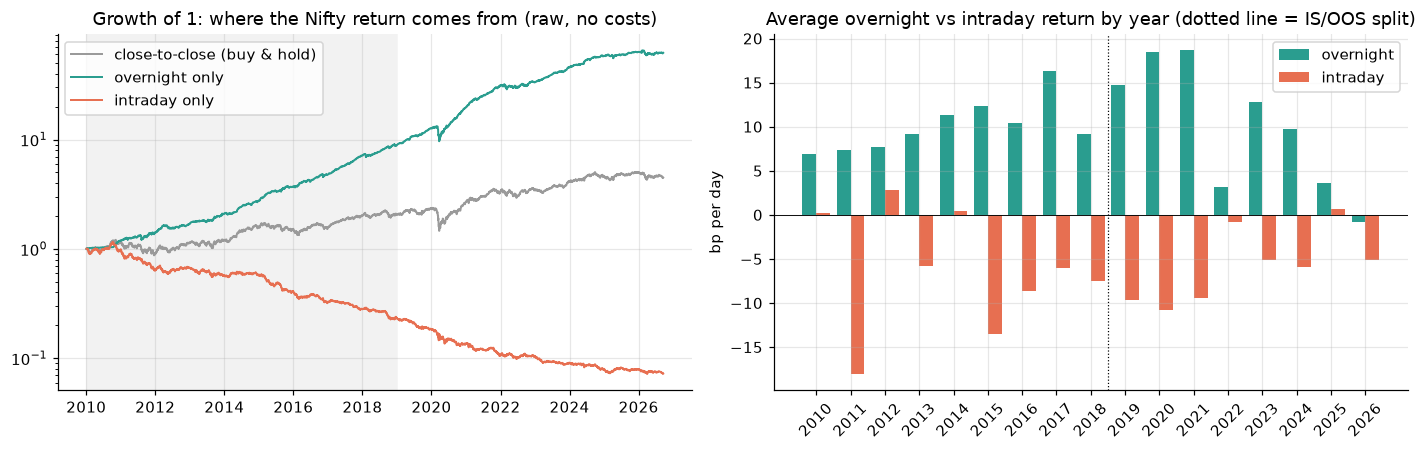

     overnight bp     n
gap                    
1.0          10.5  3102
2.0          13.6   126
3.0           6.2   767
4.0          29.7   101
5.0          13.8     8
6.0         -60.6     1
                Mon    Tue    Wed    Thu    Fri  Sat (special)
overnight bp    6.2   15.2   12.3    8.4    9.0            8.6
n             822.0  827.0  822.0  822.0  811.0            1.0


In [3]:
d = df.loc[START:].copy()
is_raw = d.loc[:IS_END]

print("In-sample 2010-18, average return per day (bp)")
print(f"  close-close: {is_raw['ret'].mean() * 1e4:.1f}")
print(f"  overnight:   {is_raw['r_on'].mean() * 1e4:.1f}")
print(f"  intraday:    {is_raw['r_id'].mean() * 1e4:.1f}")

print("In-sample 2010-18, annualised volatility")
print(f"  close-close: {is_raw['ret'].std() * np.sqrt(252):.1%}")
print(f"  overnight:   {is_raw['r_on'].std() * np.sqrt(252):.1%}")
print(f"  intraday:    {is_raw['r_id'].std() * np.sqrt(252):.1%}")
print(f"  correlation overnight vs intraday: {is_raw['r_on'].corr(is_raw['r_id']):.2f}")

# average overnight and intraday return for each year
by_year = pd.DataFrame({
    "overnight bp": d["r_on"].groupby(d.index.year).mean() * 1e4,
    "intraday bp": d["r_id"].groupby(d.index.year).mean() * 1e4,
    "nights": d["r_on"].groupby(d.index.year).size(),
})

# by number of calendar days in the gap
by_gap = pd.DataFrame({
    "overnight bp": d.groupby("gap")["r_on"].mean() * 1e4,
    "n": d.groupby("gap").size(),
})

# by weekday of the open (Sat/Sun are special trading sessions)
by_dow = pd.DataFrame({
    "overnight bp": d.groupby(d.index.dayofweek)["r_on"].mean() * 1e4,
    "n": d.groupby(d.index.dayofweek).size(),
})
day_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat (special)", "Sun (special)"]
by_dow.index = [day_names[i] for i in by_dow.index]

breakdown = pd.concat([by_year.round(1), by_gap.round(1), by_dow.round(1)], axis=1,
                      keys=["by year", "by gap (calendar days)", "by weekday of the open"])
breakdown.to_csv("results/raw_premium_breakdown.csv")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))

ax[0].plot(d.index, (1 + d["ret"]).cumprod(), color=colors["nifty"], lw=1.3, label="close-to-close (buy & hold)")
ax[0].plot(d.index, (1 + d["r_on"]).cumprod(), color=colors["overnight"], lw=1.3, label="overnight only")
ax[0].plot(d.index, (1 + d["r_id"]).cumprod(), color=colors["intraday"], lw=1.3, label="intraday only")
ax[0].set_yscale("log")
ax[0].axvspan(d.index[0], pd.Timestamp(IS_END), color=colors["insample"], zorder=0)
ax[0].legend(loc="upper left")
ax[0].set_title("Growth of 1: where the Nifty return comes from (raw, no costs)")

x = np.arange(len(by_year))
ax[1].bar(x - 0.2, by_year["overnight bp"], 0.4, color=colors["overnight"], label="overnight")
ax[1].bar(x + 0.2, by_year["intraday bp"], 0.4, color=colors["intraday"], label="intraday")
ax[1].set_xticks(x)
ax[1].set_xticklabels(by_year.index, rotation=45)
ax[1].axhline(0, color="k", lw=0.6)
ax[1].axvline(by_year.index.get_loc(2018) + 0.5, color="k", ls=":", lw=0.8)
ax[1].set_ylabel("bp per day")
ax[1].legend()
ax[1].set_title("Average overnight vs intraday return by year (dotted line = IS/OOS split)")

plt.tight_layout()
plt.savefig("results/fig1_decomposition.png")
plt.show()

print(by_gap.round(1).to_string())
print(by_dow.round(1).T.to_string())

## 3. Carry, costs and which nights to hold
A long futures position held overnight earns the spot gap minus the decay of the futures premium (the carry):

`r_fut_on[t] = r_on[t] - (rf - q) * gap[t] / 365`

So a weekend costs three nights of carry but you only get one night of premium.

Every night held needs two trades (buy at the close, sell at the open), so the cost is 2 x 2 bp. The whole capital earns the cash rate (margin is posted with pledged liquid fund units and the rest is kept in liquid funds).

`pos[t]` is the position held over the night that ends at the open of day t. It is decided at the close of day t-1 using only what is known at that time (the calendar, VIX at t-1, realised vol up to t-1).

In [4]:
def backtest(data, cost_side=COST_SIDE, div_yield=DIV_YIELD, max_gap_days=MAX_GAP_DAYS,
             fear_filter=FEAR_FILTER, fear_ratio=FEAR_RATIO, vol_target=VOL_TARGET,
             max_leverage=MAX_LEVERAGE):
    out = data.copy()

    # futures carry for the night and the overnight futures return
    out["carry"] = (out["rf_pa"] - div_yield) * out["gap"] / 365
    out["r_fut_on"] = out["r_on"] - out["carry"]

    # which nights we are allowed to hold
    if max_gap_days:
        eligible = out["gap"] <= max_gap_days
    else:
        eligible = pd.Series(True, index=out.index)

    if fear_filter:
        # VIX compared to its 60 day average, shifted by 1 so we only use the previous close
        vix_ratio = (out["vix"] / out["vix"].rolling(60).mean()).shift(1)
        eligible = eligible & (vix_ratio < fear_ratio)

    # position size
    size = pd.Series(1.0, index=out.index)
    if vol_target:
        # 20 day realised overnight vol, also known at the previous close
        on_vol = (out["r_on"].rolling(20).std() * np.sqrt(252)).shift(1)
        size = (vol_target / on_vol).clip(upper=max_leverage)

    out["pos"] = (eligible.astype(float) * size).fillna(0.0)
    out["cost"] = 2 * cost_side * out["pos"].abs()   # buy at close + sell at open
    out["r_strat"] = out["pos"] * out["r_fut_on"] + out["rf"] - out["cost"]
    out["r_excess"] = out["r_strat"] - out["rf"]

    out = out.loc[START:]
    out = out.dropna(subset=["r_fut_on"])
    out["equity"] = (1 + out["r_strat"]).cumprod()
    out["equity_nifty"] = (1 + out["ret"]).cumprod()
    return out


bt = backtest(df)
IS = bt.loc[:IS_END]
OOS = bt.loc[OOS_START:]

held_nights = bt["pos"] > 0
print(f"Nights held: {held_nights.sum()} of {len(bt)} ({held_nights.mean():.1%})")
print(f"Average carry on held nights: {bt.loc[held_nights, 'carry'].mean() * 1e4:.1f} bp")
print(f"Cost per held night: {COST_SIDE * 2e4:.0f} bp")
print(f"Gross premium on held nights (IS): {IS.loc[IS['pos'] > 0, 'r_on'].mean() * 1e4:.1f} bp")

Nights held: 3102 of 4105 (75.6%)
Average carry on held nights: 1.5 bp
Cost per held night: 4 bp
Gross premium on held nights (IS): 9.4 bp


## 4. Performance metrics
Sharpe is calculated on the excess return over the cash rate. Cash averaged 6.6% over this period, so it is a harder bar to beat than zero.

In [5]:
def metrics(r_strat, r_excess, rf, label=""):
    years = len(r_strat) / 252
    equity = (1 + r_strat).cumprod()
    drawdown = equity / equity.cummax() - 1
    max_dd = drawdown.min()

    cagr = equity.iloc[-1] ** (1 / years) - 1
    excess_mean = r_excess.mean() * 252
    excess_vol = r_excess.std() * np.sqrt(252)
    downside_vol = r_excess[r_excess < 0].std() * np.sqrt(252)

    if excess_vol > 0:
        sharpe = excess_mean / excess_vol
    else:
        sharpe = np.nan

    if downside_vol > 0:
        sortino = excess_mean / downside_vol
    else:
        sortino = np.nan

    if max_dd < 0:
        calmar = cagr / abs(max_dd)
    else:
        calmar = np.nan

    # hit rate ignores the days with zero excess return (nights we were flat)
    hit_rate = (r_excess[r_excess != 0] > 0).mean()

    return pd.Series({
        "CAGR": cagr,
        "Cash rate (avg)": rf.mean() * 252,
        "Excess return p.a.": excess_mean,
        "Volatility p.a.": r_strat.std() * np.sqrt(252),
        "Sharpe (excess)": sharpe,
        "Sortino": sortino,
        "Max drawdown": max_dd,
        "Calmar": calmar,
        "Worst day": r_strat.min(),
        "Hit rate (nights)": hit_rate,
        "Years": years,
    }, name=label)


def strat_metrics(res, label=""):
    return metrics(res["r_strat"], res["r_excess"], res["rf"], label)


def nifty_metrics(res, label=""):
    return metrics(res["ret"], res["ret"] - res["rf"], res["rf"], label)


tbl = pd.concat([
    strat_metrics(bt, "Strategy full 2010-26"),
    strat_metrics(IS, "Strategy IS 2010-18"),
    strat_metrics(OOS, "Strategy OOS 2019-26"),
    nifty_metrics(bt, "Nifty B&H full"),
    nifty_metrics(IS, "Nifty B&H IS"),
    nifty_metrics(OOS, "Nifty B&H OOS"),
], axis=1)
tbl.to_csv("results/metrics.csv")
print(tbl.round(3).to_string())

                    Strategy full 2010-26  Strategy IS 2010-18  Strategy OOS 2019-26  Nifty B&H full  Nifty B&H IS  Nifty B&H OOS
CAGR                                0.172                0.152                 0.196           0.097         0.088          0.107
Cash rate (avg)                     0.066                0.074                 0.056           0.066         0.074          0.056
Excess return p.a.                  0.096                0.069                 0.126           0.040         0.022          0.060
Volatility p.a.                     0.076                0.069                 0.083           0.164         0.156          0.173
Sharpe (excess)                     1.264                1.011                 1.519           0.242         0.142          0.348
Sortino                             1.262                1.011                 1.500           0.319         0.207          0.420
Max drawdown                       -0.150               -0.081                -0.150      

## 5. Yearly returns and scorecard

In [6]:
def compound(r):
    return (1 + r).prod() - 1


def sharpe(r):
    return r.mean() / r.std() * np.sqrt(252)


year = bt.index.year
yr = pd.DataFrame({
    "Strategy total": bt["r_strat"].groupby(year).apply(compound),
    "Strategy excess": bt["r_excess"].groupby(year).apply(compound),
    "Nifty": bt["ret"].groupby(year).apply(compound),
    "Cash": bt["rf"].groupby(year).apply(compound),
    "Nights held": (bt["pos"] > 0).groupby(year).sum(),
    "Sharpe": bt["r_excess"].groupby(year).apply(sharpe),
})
yr["Sample"] = np.where(yr.index <= 2018, "IS", "OOS")
yr.to_csv("results/calendar_year_returns.csv")

last7 = yr.loc[2019:2025]
nifty_excess = bt["ret"] - bt["rf"]
beta = np.cov(bt["r_excess"], nifty_excess)[0, 1] / np.var(nifty_excess)

score = pd.Series({
    "Sharpe net, full 2010-26": tbl.loc["Sharpe (excess)", "Strategy full 2010-26"],
    "Sharpe net, IS 2010-18": tbl.loc["Sharpe (excess)", "Strategy IS 2010-18"],
    "Sharpe net, OOS 2019-26": tbl.loc["Sharpe (excess)", "Strategy OOS 2019-26"],
    "Positive excess years 2019-25 (of 7)": int((last7["Strategy excess"] > 0).sum()),
    "Positive total years 2019-25 (of 7)": int((last7["Strategy total"] > 0).sum()),
    "Correlation to Nifty (daily excess)": bt["r_excess"].corr(nifty_excess),
    "Beta to Nifty": beta,
    "Time in market (nights)": (bt["pos"] > 0).mean(),
})
score.to_csv("results/scorecard.csv")
print(score.round(3).to_string())

yr.round(4)

Sharpe net, full 2010-26                1.264
Sharpe net, IS 2010-18                  1.011
Sharpe net, OOS 2019-26                 1.519
Positive excess years 2019-25 (of 7)    6.000
Positive total years 2019-25 (of 7)     7.000
Correlation to Nifty (daily excess)     0.388
Beta to Nifty                           0.178
Time in market (nights)                 0.756


,Strategy total,Strategy excess,Nifty,Cash,Nights held,Sharpe,Sample
Date,,,,,,,
2010,0.0345,-0.0253,0.1795,0.0613,194,-0.9560,IS
2011,0.0343,-0.0236,-0.2462,0.0593,178,-0.1996,IS
2012,0.1205,0.0306,0.2770,0.0872,178,0.4812,IS
2013,0.1211,0.0270,0.0676,0.0917,187,0.3986,IS
2014,0.1831,0.0861,0.3139,0.0893,178,1.7492,IS
2015,0.3175,0.2161,-0.0406,0.0834,185,3.3118,IS
2016,0.1598,0.0824,0.0301,0.0715,187,0.9669,IS
2017,0.2712,0.1930,0.2865,0.0656,193,4.3125,IS
2018,0.1144,0.0462,0.0315,0.0652,182,0.6718,IS


## 6. Charts

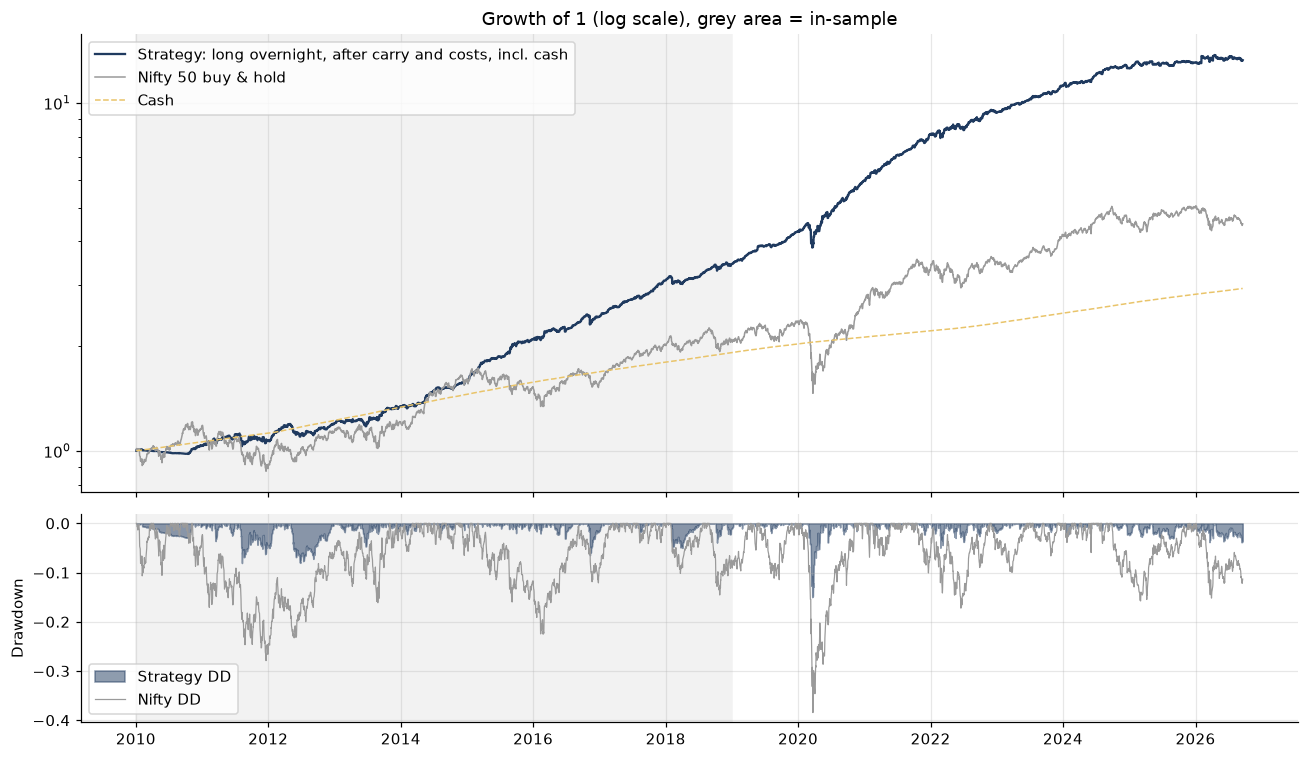

In [7]:
fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})

cash_equity = (1 + bt["rf"]).cumprod()
ax[0].plot(bt.index, bt["equity"], color=colors["strat"], lw=1.5, label="Strategy: long overnight, after carry and costs, incl. cash")
ax[0].plot(bt.index, bt["equity_nifty"], color=colors["nifty"], lw=1.0, label="Nifty 50 buy & hold")
ax[0].plot(bt.index, cash_equity, color=colors["cash"], lw=1.0, ls="--", label="Cash")
ax[0].set_yscale("log")
ax[0].legend(loc="upper left")
ax[0].set_title("Growth of 1 (log scale), grey area = in-sample")

dd_strat = bt["equity"] / bt["equity"].cummax() - 1
dd_nifty = bt["equity_nifty"] / bt["equity_nifty"].cummax() - 1
ax[1].fill_between(bt.index, dd_strat, 0, color=colors["strat"], alpha=0.5, label="Strategy DD")
ax[1].plot(bt.index, dd_nifty, color=colors["nifty"], lw=0.8, label="Nifty DD")
ax[1].legend(loc="lower left")
ax[1].set_ylabel("Drawdown")

for a in ax:
    a.axvspan(bt.index[0], pd.Timestamp(IS_END), color=colors["insample"], zorder=0)

plt.tight_layout()
plt.savefig("results/fig2_equity_drawdown.png")
plt.show()

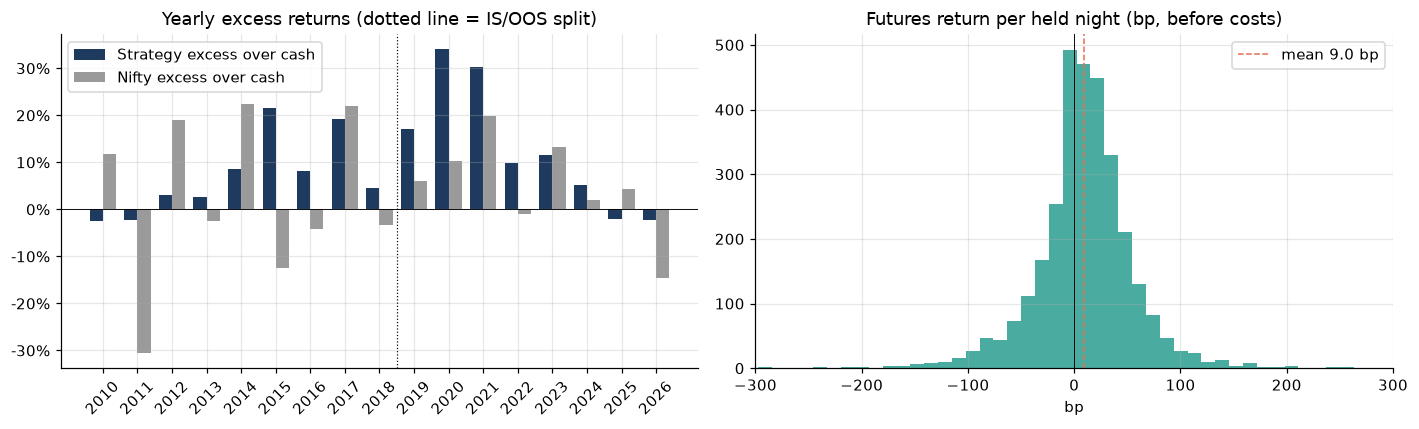

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

x = np.arange(len(yr))
w = 0.38
ax[0].bar(x - w / 2, yr["Strategy excess"], w, color=colors["strat"], label="Strategy excess over cash")
ax[0].bar(x + w / 2, yr["Nifty"] - yr["Cash"], w, color=colors["nifty"], label="Nifty excess over cash")
ax[0].set_xticks(x)
ax[0].set_xticklabels(yr.index, rotation=45)
ax[0].axhline(0, color="k", lw=0.6)
ax[0].axvline(yr.index.get_loc(2018) + 0.5, color="k", ls=":", lw=0.8)
ax[0].legend()
ax[0].set_title("Yearly excess returns (dotted line = IS/OOS split)")
ax[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))

held = bt[bt["pos"] > 0]
mean_bp = held["r_fut_on"].mean() * 1e4
ax[1].hist(held["r_fut_on"] * 1e4, bins=80, color=colors["overnight"], alpha=0.85)
ax[1].axvline(0, color="k", lw=0.6)
ax[1].axvline(mean_bp, color=colors["intraday"], ls="--", lw=1, label=f"mean {mean_bp:.1f} bp")
ax[1].set_xlim(-300, 300)
ax[1].legend()
ax[1].set_title("Futures return per held night (bp, before costs)")
ax[1].set_xlabel("bp")

plt.tight_layout()
plt.savefig("results/fig3_years_and_nights.png")
plt.show()

## 7. Cost sensitivity and STT
The edge is around 7.5 bp per night before costs (after carry), and a round trip costs 4 bp in the base case, so costs matter a lot. The first table shows the Sharpe at different cost levels. The second one converts different STT rates into a cost per side (STT on futures has been raised twice since 2023).

In [9]:
cost_levels = [0, 0.0001, 0.00015, 0.0002, 0.0003, 0.0004, 0.0005]
cost_results = {}
for c in cost_levels:
    res = backtest(df, cost_side=c)
    cost_results[f"{c * 1e4:.1f} bp/side"] = strat_metrics(res)

cost_tbl = pd.DataFrame(cost_results)
cost_tbl = cost_tbl.loc[["Excess return p.a.", "Sharpe (excess)", "Max drawdown"]]
cost_tbl.to_csv("results/sensitivity_costs.csv")
print(cost_tbl.round(3).to_string())

# break-even cost per side = average futures return on held nights / 2 trades
be_full = bt.loc[bt["pos"] > 0, "r_fut_on"].mean() / 2
be_is = IS.loc[IS["pos"] > 0, "r_fut_on"].mean() / 2
be_oos = OOS.loc[OOS["pos"] > 0, "r_fut_on"].mean() / 2
print()
print(f"Break-even cost per side: {be_full * 1e4:.2f} bp (full period), {be_is * 1e4:.2f} bp (IS), {be_oos * 1e4:.2f} bp (OOS)")


# cost per side built up from the fee schedule:
#   STT is charged on the sell side only -> half of it per side
#   exchange charge 0.00173%
#   stamp duty 0.002% on the buy side only -> half of it per side
#   brokerage Rs 20 per lot
#   GST 18% on exchange charge + brokerage
#   slippage 0.7 bp
def cost_from_stt(stt, slippage=0.00007, exch=0.0000173, stamp=0.00002, brok=0.0000011):
    return stt / 2 + exch + stamp / 2 + brok + 0.18 * (exch + brok) + slippage


stt_cases = [
    (0.0001, "until Mar-2023"),
    (0.000125, "Apr-2023 to Sep-2024"),
    (0.0002, "since Oct-2024 (base)"),
    (0.0003, "hypothetical hike"),
    (0.0005, "hypothetical hike"),
]
stt_rows = []
for stt, regime in stt_cases:
    c = cost_from_stt(stt)
    res = backtest(df, cost_side=c)
    stt_rows.append({
        "STT (sell side)": f"{stt:.4%}",
        "regime": regime,
        "cost/side bp": c * 1e4,
        "Sharpe full": strat_metrics(res)["Sharpe (excess)"],
        "Sharpe OOS": strat_metrics(res.loc[OOS_START:])["Sharpe (excess)"],
    })

stt_tbl = pd.DataFrame(stt_rows)
stt_tbl.to_csv("results/sensitivity_stt.csv", index=False)
stt_tbl.round(2)

                    0.0 bp/side  1.0 bp/side  1.5 bp/side  2.0 bp/side  3.0 bp/side  4.0 bp/side  5.0 bp/side
Excess return p.a.        0.172        0.134        0.115        0.096        0.058        0.019       -0.019
Sharpe (excess)           2.266        1.766        1.516        1.264        0.762        0.258       -0.246
Max drawdown             -0.146       -0.148       -0.149       -0.150       -0.152       -0.154       -0.205

Break-even cost per side: 4.51 bp (full period), 3.83 bp (IS), 5.30 bp (OOS)


,STT (sell side),regime,cost/side bp,Sharpe full,Sharpe OOS
0,0.0100%,until Mar-2023,1.52,1.51,1.74
1,0.0125%,Apr-2023 to Sep-2024,1.64,1.44,1.68
2,0.0200%,since Oct-2024 (base),2.02,1.26,1.51
3,0.0300%,hypothetical hike,2.52,1.00,1.28
4,0.0500%,hypothetical hike,3.52,0.50,0.82


## 8. Variants: in-sample vs out-of-sample
The base rule only has one real choice in it (skip the multi-night gaps). The optional filters were deliberately not added to the base strategy. The table below shows what each of them does in both periods.

                                            IS Sharpe  OOS Sharpe  Full Sharpe  Full excess p.a.  Max DD  Nights held %
every night (no filter)                         1.081       1.058        1.057             0.102  -0.273          1.000
skip multi-night gaps (BASE)                    1.011       1.519        1.264             0.096  -0.150          0.756
base + fear filter (VIX >= 1.3x avg, flat)      0.867       1.829        1.323             0.086  -0.080          0.713
base + vol target 10% (overnight vol)           0.980       1.732        1.325             0.083  -0.086          0.756
base + fear + vol target                        0.850       1.943        1.344             0.079  -0.078          0.713
weekends only (the skipped nights)              0.238      -0.130        0.020             0.001  -0.187          0.214


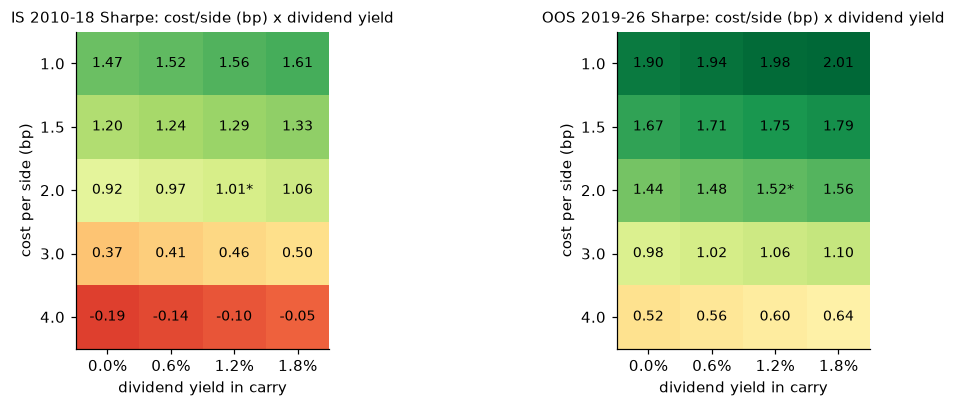

In [10]:
def sharpe_between(res, start=None, end=None):
    ex = res.loc[start:end, "r_excess"]
    if ex.std() > 0:
        return ex.mean() / ex.std() * np.sqrt(252)
    return np.nan


variants = {
    "every night (no filter)": {"max_gap_days": None},
    "skip multi-night gaps (BASE)": {},
    "base + fear filter (VIX >= 1.3x avg, flat)": {"fear_filter": True},
    "base + vol target 10% (overnight vol)": {"vol_target": 0.10},
    "base + fear + vol target": {"fear_filter": True, "vol_target": 0.10},
    "weekends only (the skipped nights)": {"max_gap_days": None},
}

rows = []
for name, kwargs in variants.items():
    res = backtest(df, **kwargs)

    if name.startswith("weekends only"):
        # opposite of the base: only hold the nights with a gap of 3+ days
        res["pos"] = (res["gap"] >= 3).astype(float)
        res["cost"] = 2 * COST_SIDE * res["pos"]
        res["r_strat"] = res["pos"] * res["r_fut_on"] + res["rf"] - res["cost"]
        res["r_excess"] = res["r_strat"] - res["rf"]

    equity = (1 + res["r_strat"]).cumprod()
    max_dd = (equity / equity.cummax() - 1).min()

    row = pd.Series({
        "IS Sharpe": sharpe_between(res, None, IS_END),
        "OOS Sharpe": sharpe_between(res, OOS_START, None),
        "Full Sharpe": sharpe_between(res),
        "Full excess p.a.": res["r_excess"].mean() * 252,
        "Max DD": max_dd,
        "Nights held %": (res["pos"] > 0).mean(),
    }, name=name)
    rows.append(row)

var_tbl = pd.DataFrame(rows)
var_tbl.to_csv("results/sensitivity_variants.csv")
print(var_tbl.round(3).to_string())

# grid of cost per side x dividend yield
cost_grid = [0.0001, 0.00015, 0.0002, 0.0003, 0.0004]
div_grid = [0.0, 0.006, 0.012, 0.018]
row_labels = [f"{c * 1e4:.1f}" for c in cost_grid]
col_labels = [f"{q:.1%}" for q in div_grid]

grid_is = pd.DataFrame(index=row_labels, columns=col_labels, dtype=float)
grid_oos = grid_is.copy()

for c in cost_grid:
    for q in div_grid:
        res = backtest(df, cost_side=c, div_yield=q)
        r_lab = f"{c * 1e4:.1f}"
        c_lab = f"{q:.1%}"
        grid_is.loc[r_lab, c_lab] = sharpe_between(res, None, IS_END)
        grid_oos.loc[r_lab, c_lab] = sharpe_between(res, OOS_START, None)

grid_is.to_csv("results/sensitivity_IS_cost_x_divyield.csv")
grid_oos.to_csv("results/sensitivity_OOS_cost_x_divyield.csv")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
titles = ["IS 2010-18 Sharpe: cost/side (bp) x dividend yield",
          "OOS 2019-26 Sharpe: cost/side (bp) x dividend yield"]

for a, grid, title in zip(ax, [grid_is, grid_oos], titles):
    a.imshow(grid.values.astype(float), cmap="RdYlGn", vmin=-0.5, vmax=2.0)
    a.set_xticks(range(len(grid.columns)))
    a.set_xticklabels(grid.columns)
    a.set_yticks(range(len(grid.index)))
    a.set_yticklabels(grid.index)
    a.grid(False)
    a.set_xlabel("dividend yield in carry")
    a.set_ylabel("cost per side (bp)")
    a.set_title(title, fontsize=10)

    # write the Sharpe in each cell, * = base case
    for i in range(len(grid.index)):
        for j in range(len(grid.columns)):
            txt = f"{grid.values[i, j]:.2f}"
            if grid.index[i] == "2.0" and grid.columns[j] == "1.2%":
                txt = txt + "*"
            a.text(j, i, txt, ha="center", va="center", fontsize=9)

plt.tight_layout()
plt.savefig("results/fig4_sensitivity.png")
plt.show()

## 9. Risk
The premium is a payment for taking gap risk, so this section looks at the gaps: how big they are, how they cluster, and what the strategy did on the worst days for the index. There are also two risks that don't show up in the data: fees and crowding (see limitations).

In [11]:
held = bt[bt["pos"] > 0]

worst = held.nsmallest(8, "r_fut_on")[["r_on", "r_fut_on", "r_strat", "ret", "vix", "gap"]]
print("Worst 8 held nights:")
print(worst.round(4).to_string())

worst_days = bt["ret"].nsmallest(10)
strat_avg = bt.loc[worst_days.index, "r_strat"].mean()
n_held = int((bt.loc[worst_days.index, "pos"] > 0).sum())
print()
print(f"Nifty's 10 worst close-to-close days: strategy avg {strat_avg:.2%} vs Nifty {worst_days.mean():.2%}")
print(f"Strategy held the night into {n_held} of them")

r = held["r_fut_on"]
var_99 = r.quantile(0.01)
tail = pd.Series({
    "Nights held": len(held),
    "Mean bp": r.mean() * 1e4,
    "Median bp": r.median() * 1e4,
    "Std bp": r.std() * 1e4,
    "Skew": r.skew(),
    "Kurtosis": r.kurt(),
    "P(loss)": (r < 0).mean(),
    "Nights < -2%": int((r < -0.02).sum()),
    "Nights > +2%": int((r > 0.02).sum()),
    "VaR 99% (bp)": var_99 * 1e4,
    "ES 99% (bp)": r[r <= var_99].mean() * 1e4,
})
tail.to_csv("results/tail_stats.csv")
print()
print(tail.round(2).to_string())

vix_q = pd.qcut(held["vix"].shift(1), 4, labels=["VIX Q1 (calm)", "Q2", "Q3", "Q4 (fear)"])
premium_by_vix = held["r_fut_on"].groupby(vix_q).mean() * 1e4
print()
print("Premium by VIX quartile at the prior close (bp per night, after carry):")
print(premium_by_vix.round(1).to_string())

Worst 8 held nights:
              r_on  r_fut_on  r_strat     ret    vix  gap
Date                                                     
2016-11-09 -0.0557   -0.0559  -0.0560 -0.0131  16.62  1.0
2020-03-13 -0.0503   -0.0504  -0.0506  0.0381  51.47  1.0
2020-03-19 -0.0479   -0.0480  -0.0482 -0.0242  72.20  1.0
2020-03-12 -0.0400   -0.0401  -0.0403 -0.0830  41.16  1.0
2020-06-12 -0.0361   -0.0361  -0.0364  0.0072  30.82  1.0
2018-02-06 -0.0348   -0.0350  -0.0351 -0.0158  20.02  1.0
2011-08-09 -0.0333   -0.0335  -0.0336 -0.0089  34.88  1.0
2022-02-24 -0.0301   -0.0302  -0.0305 -0.0478  31.98  1.0

Nifty's 10 worst close-to-close days: strategy avg -0.60% vs Nifty -6.61%
Strategy held the night into 4 of them

Nights held     3102.00
Mean bp            9.02
Median bp          9.98
Std bp            54.76
Skew              -0.86
Kurtosis          17.84
P(loss)            0.38
Nights < -2%      17.00
Nights > +2%      16.00
VaR 99% (bp)    -145.67
ES 99% (bp)     -249.96

Premium by VIX quar

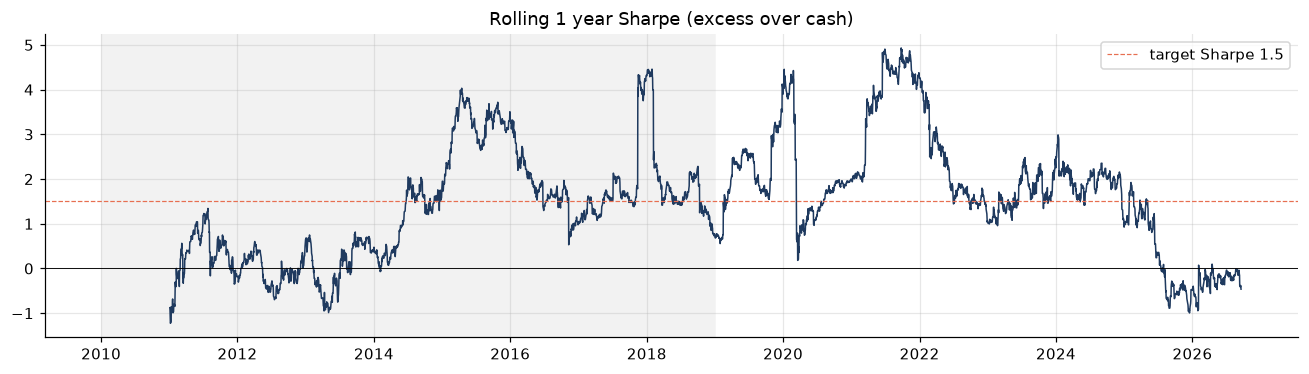

In [12]:
roll_mean = bt["r_excess"].rolling(252).mean()
roll_std = bt["r_excess"].rolling(252).std()
roll_sharpe = roll_mean / roll_std * np.sqrt(252)

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(roll_sharpe.index, roll_sharpe, color=colors["strat"], lw=1)
ax.axhline(0, color="k", lw=0.6)
ax.axhline(1.5, color=colors["intraday"], ls="--", lw=0.8, label="target Sharpe 1.5")
ax.axvspan(bt.index[0], pd.Timestamp(IS_END), color=colors["insample"], zorder=0)
ax.legend()
ax.set_title("Rolling 1 year Sharpe (excess over cash)")

plt.tight_layout()
plt.savefig("results/fig5_rolling_sharpe.png")
plt.show()

In [13]:
save_cols = ["open", "close", "vix", "gap", "rf", "ret", "r_on", "r_id", "carry", "r_fut_on",
             "pos", "cost", "r_strat", "r_excess", "equity", "equity_nifty"]
bt[save_cols].to_csv("results/daily_backtest.csv")
print("Saved all tables and figures in results/")

Saved all tables and figures in results/


## 10. Limitations
1. Spot index used instead of futures. The carry decay is modelled, but the basis noise at the open and close is not. The 0.7 bp slippage is meant to cover this.
2. Fills at the official open and close. Live, you would sell into the 09:15 opening prints and buy in the closing window. Nifty futures are liquid at both times but the open can be volatile.
3. Fees can change. STT on futures went up from 0.01% to 0.02% in two steps (2023 and 2024). The break-even is about 3.8 bp per side, which is an STT of about 0.055%. Most of the backtest period had lower fees than today.
4. It's a known anomaly. The overnight premium has been documented in many markets, so there is a risk it gets crowded or arbitraged away. The by-year table can be used to keep an eye on it.
5. Beta is not zero. The strategy is long the index for about 16 hours a day. Correlation to Nifty is about 0.4 and beta about 0.2, so it is low beta but not market neutral.